In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = sns.load_dataset('titanic')

In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [5]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [6]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [7]:
df['age'] = df['age'].fillna(df['age'].median())

In [8]:
df['age'].isnull().sum()

np.int64(0)

In [9]:
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

In [10]:
df['embarked'].isnull().sum()

np.int64(0)

In [11]:
df = df.drop(columns=['deck'])

In [12]:
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64

In [13]:
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

In [14]:
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

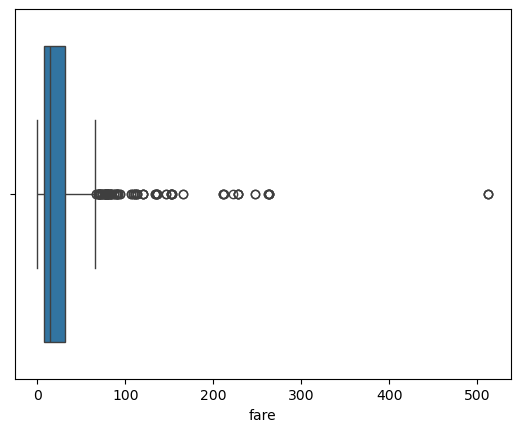

In [15]:
sns.boxplot(x=df['fare'])
plt.show()

In [16]:
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
supper = Q3 + 1.5 * IQR
median = df['fare'].median()
df.loc[(df['fare'] < lower)|(df['fare'] > supper), 'fare'] = median

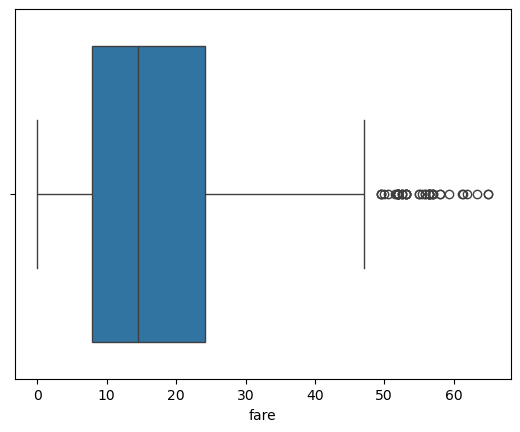

In [17]:
sns.boxplot(x=df['fare'])
plt.show()

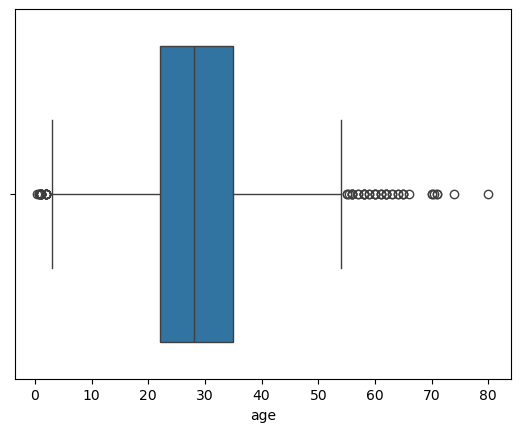

In [18]:
sns.boxplot(x=df['age'])
plt.show()

In [19]:
Q1 = df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 -Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
median = df['age'].median()
df.loc[(df['age'] < lower) |(df['age'] > upper), 'age'] = median

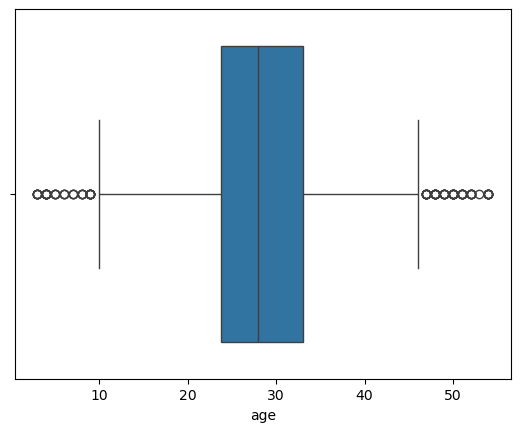

In [20]:
sns.boxplot(x=df['age'])
plt.show()

In [21]:
df = pd.get_dummies(df, columns=['sex'], dtype=int)

In [22]:
df = pd.get_dummies(df,columns=['embarked'],dtype=int)

In [23]:
df['class'] = df['class'].map({
    'First':1,
    'Second':2,
    'Third':3
})

In [24]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df_normalized = df.copy()
df_normalized[['age','fare']] = scaler.fit_transform(df[['age','fare']])

In [25]:
df_normalized[['age','fare']].head()

,age,fare
0,0.372549,0.111538
1,0.686275,0.222372
2,0.450980,0.121923
3,0.627451,0.816923
4,0.627451,0.123846


In [34]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_standardized = df.copy()
df_standardized[['age','fare']] = scaler.fit_transform(df[['age','fare']])

In [27]:
df_standardized[['age','fare']].head()

,age,fare
0,-0.661724,-0.797554
1,0.972921,-0.230556
2,-0.253063,-0.744429
3,0.666425,2.811012
4,0.666425,-0.734591


In [28]:
df_standardized[['age','fare']].mean()

age    -1.913920e-16
fare   -9.569599e-17
dtype: float64

In [29]:
df_standardized[['age','fare']].std()

age     1.000562
fare    1.000562
dtype: float64

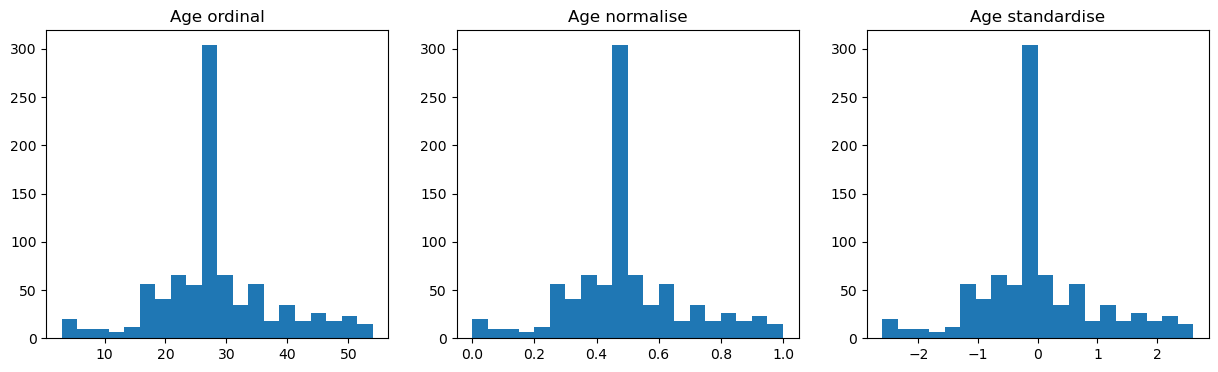

In [35]:
plt.figure(figsize = (15,4))
plt.subplot(1,3,1)
plt.hist(df['age'].dropna(),bins=20)
plt.title('Age ordinal')
plt.subplot(1,3,2)
plt.hist(df_normalized['age'].dropna(),bins=20)
plt.title('Age normalise')
plt.subplot(1,3,3)
plt.hist(df_standardized['age'].dropna(),bins=20)
plt.title('Age standardise')
plt.show()
           

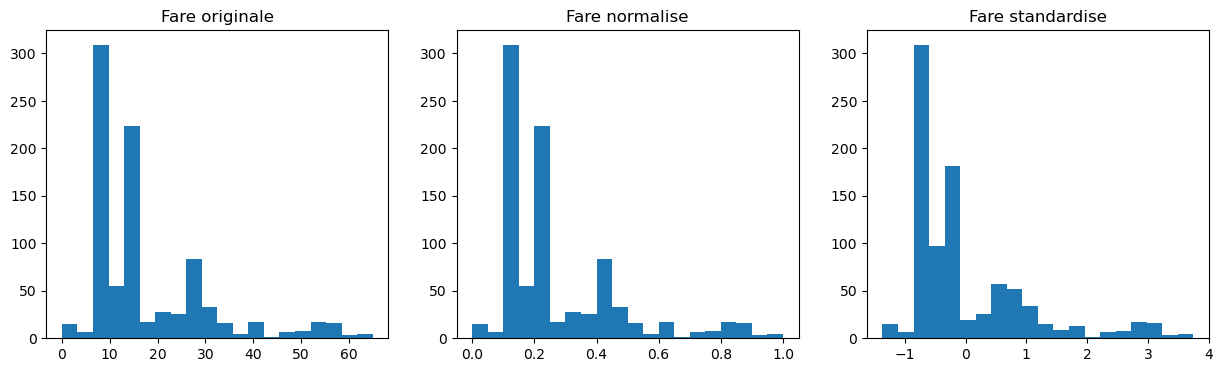

In [37]:
plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
plt.hist(df['fare'].dropna(),bins=20)
plt.title('Fare originale')
plt.subplot(1,3,2)
plt.hist(df_normalized['fare'].dropna(),bins=20)
plt.title('Fare normalise')
plt.subplot(1,3,3)
plt.hist(df_standardized['fare'].dropna(),bins=20)
plt.title('Fare standardise')
plt.show()

In [38]:
df['survived'].value_counts()

survived
0    549
1    342
Name: count, dtype: int64

In [39]:
df['survived'].value_counts(normalize=True)*100

survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

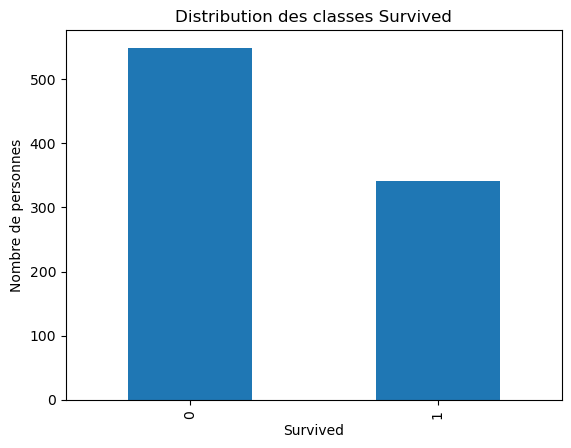

In [41]:
import matplotlib.pyplot as plt
df['survived'].value_counts().plot(kind='bar')
plt.title('Distribution des classes Survived')
plt.xlabel('Survived')
plt.ylabel('Nombre de personnes')
plt.show()

In [42]:
from imblearn.under_sampling import RandomUnderSampler
x = df.drop('survived',axis=1)
y = df['survived']
x = pd.get_dummies(x,drop_first=True)
x = x.fillna(x.median())
rus = RandomUnderSampler(random_state=42)
x_under,y_under = rus.fit_resample(x,y)
print(y_under.value_counts())

survived
0    342
1    342
Name: count, dtype: int64


In [43]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
x_over,y_over = smote.fit_resample(x,y)
print(y_over.value_counts())

survived
0    549
1    549
Name: count, dtype: int64


In [44]:
print("Donnees originales:")
print(df['survived'].value_counts())
print("\nApres undersampling:")
print(y_under.value_counts())
print("\nApres SMOTE:")
print(y_over.value_counts())

Donnees originales:
survived
0    549
1    342
Name: count, dtype: int64

Apres undersampling:
survived
0    342
1    342
Name: count, dtype: int64

Apres SMOTE:
survived
0    549
1    549
Name: count, dtype: int64
